In [1]:
import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

import visualization as vis
import matplotlib.pyplot as plt

In [2]:
misr_obs_file = '../MISR_OBS_CAMP2Ex_RF17_default.nc'
misr_obs_movie_out = './MISR_OBS_CAMP2Ex_RF17_default_movie/'

at3d_obs_file = '../AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
at3d_obs_movie_out = './AT3D_OBS_CAMP2Ex_RF17_default_1400_movie/'

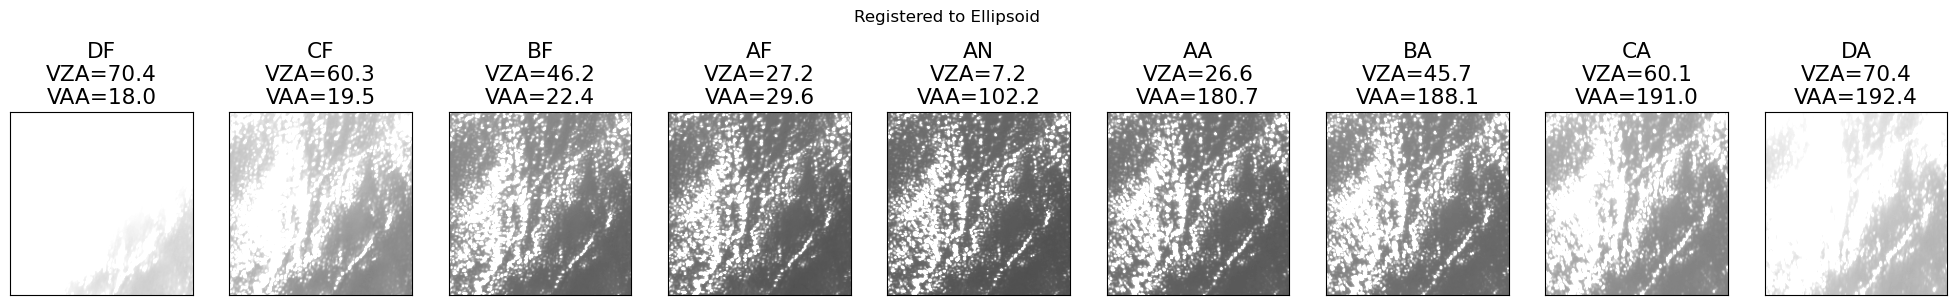

In [3]:
fig, ax = plt.subplots(1, 9, figsize=(25, 4))
vis.plot_misr_data(misr_obs_file, fig, ax, vmax=0.09, cbar_loc=None)

Movie saved at ./MISR_OBS_CAMP2Ex_RF17_default_movie/movie.gif


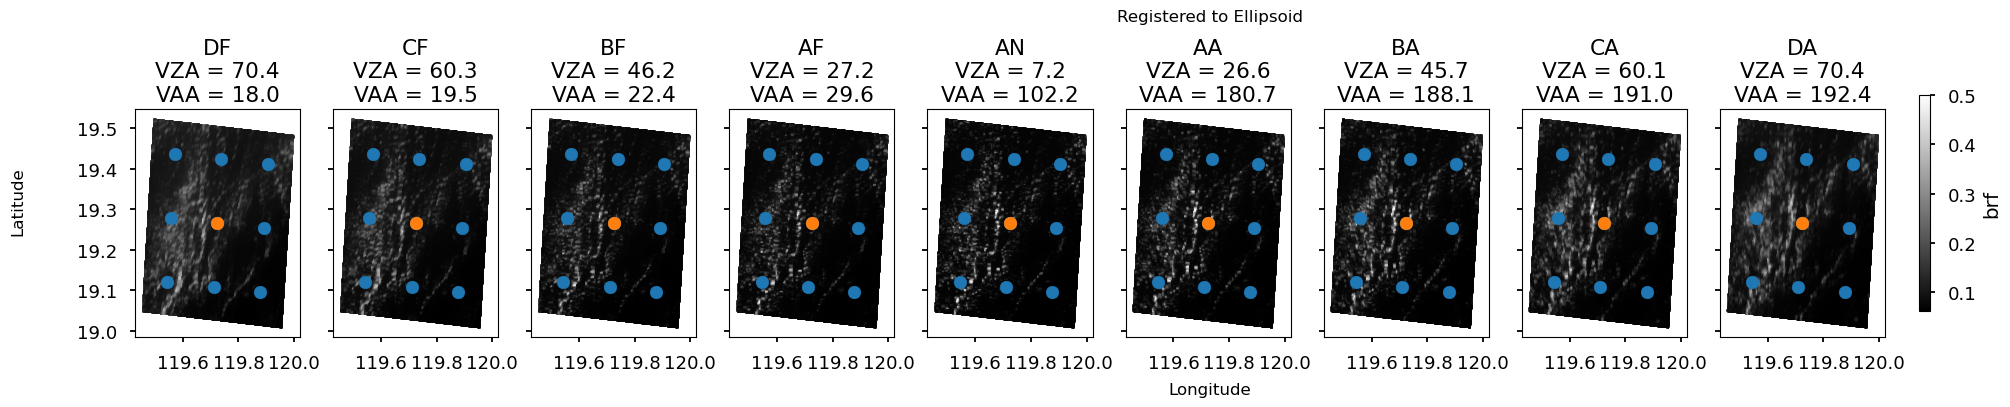

In [4]:
fig, ax = plt.subplots(1, 9, figsize=(25, 4), sharex=True, sharey=True)
vis.plot_misr_data_map(misr_obs_file, fig, ax, vmax=0.5, cbar_loc='right', s=2.0)
vis.overlay_sampling(misr_obs_file, fig, ax)
fig.subplots_adjust(top=0.73, bottom=0.16, left=0.07, right=0.77)

vis.misr_obs_frames(misr_obs_file, misr_obs_movie_out, s=2, overlay_sampling=False)
vis.make_movie(misr_obs_movie_out + 'movie.gif', nframes=9, fps=10)

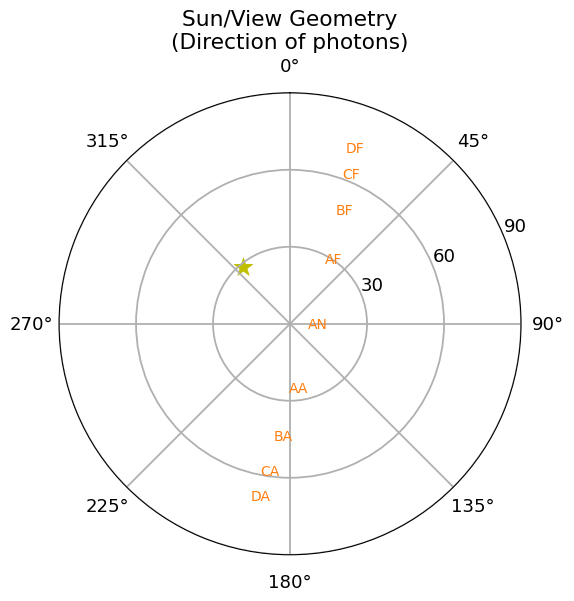

In [5]:
f, ax = plt.subplots(1, 1, figsize = (6, 6), subplot_kw={'projection': 'polar'})
vis.plot_sun_view_grometry(misr_obs_file, ax)

Movie saved at ./AT3D_OBS_CAMP2Ex_RF17_default_1400_movie/movie.gif


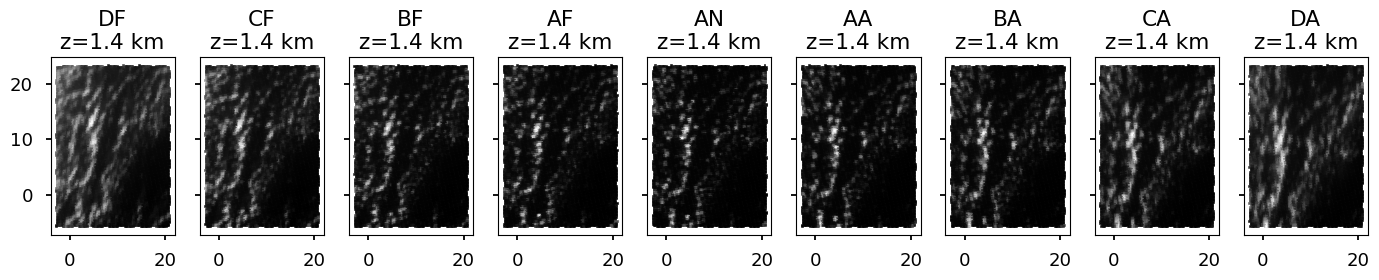

In [6]:
fig, ax = plt.subplots(1, 9, figsize=(17, 2.3), sharex=True, sharey=True)
vis.plot_measurements(at3d_obs_file, 'MISR', fig, ax, s=2)

vis.at3d_obs_frames(at3d_obs_file, 'MISR', at3d_obs_movie_out, s=10)
vis.make_movie(at3d_obs_movie_out + 'movie.gif', nframes=9, fps=10)

In [14]:
import util
import xarray as xr
import numpy as np

In [11]:
misr_obs = xr.load_dataset(misr_obs_file)

In [12]:
misr_obs

<xarray.Dataset>
Dimensions:     (camera: 9, y275: 192, x275: 192, y17600: 3, x17600: 3)
Coordinates:
  * camera      (camera) object 'DF' 'CF' 'BF' 'AF' 'AN' 'AA' 'BA' 'CA' 'DA'
Dimensions without coordinates: y275, x275, y17600, x17600
Data variables: (12/15)
    brf         (camera, y275, x275) float64 0.1213 0.1352 ... 0.06461 0.06443
    lat275      (y275, x275) float64 19.52 19.52 19.52 ... 19.01 19.01 19.01
    lon275      (y275, x275) float64 119.5 119.5 119.5 ... 119.9 119.9 120.0
    lat17600    (y17600, x17600) float64 19.44 19.42 19.41 ... 19.12 19.11 19.09
    lon17600    (y17600, x17600) float64 119.6 119.7 119.9 ... 119.5 119.7 119.9
    SZA         (y17600, x17600) float64 28.87 28.76 28.65 ... 28.63 28.52 28.41
    ...          ...
    VZA_center  (camera) float64 70.42 60.33 46.15 27.19 ... 45.68 60.07 70.36
    VAA_center  (camera) float64 17.98 19.54 22.38 29.62 ... 188.1 191.0 192.4
    SZA_center  float64 28.64
    SAA_center  float64 320.5
    center_lat  float64 19.27
    center_lon  float64 119.7
Attributes:
    orbit:    105254
    path:     117
    blocks:   [75 75]

In [4]:
obs = util.load_sensor_dict(at3d_obs_file)

In [7]:
obs['MISR']['sensor_list'][0]

<xarray.Dataset>
Dimensions:            (stokes_index: 4, npixels: 9131, nrays: 9131)
Coordinates:
  * stokes_index       (stokes_index) object 'I' 'Q' 'U' 'V'
Dimensions without coordinates: npixels, nrays
Data variables: (12/16)
    wavelength         float64 ...
    stokes             (stokes_index) bool True False False False
    cam_x              (npixels) float64 ...
    cam_y              (npixels) float64 ...
    cam_z              (npixels) float64 1.4 1.4 1.4 1.4 1.4 ... 1.4 1.4 1.4 1.4
    cam_mu             (npixels) float64 0.3332 0.3332 0.3332 ... 0.3382 0.3383
    ...                 ...
    ray_y              (nrays) float64 ...
    ray_z              (nrays) float64 1.4 1.4 1.4 1.4 1.4 ... 1.4 1.4 1.4 1.4
    pixel_index        (nrays) int64 ...
    ray_weight         (nrays) float64 ...
    use_subpixel_rays  bool False
    I                  (nrays) float64 ...
Attributes:
    name:     DF
    mu0:      0.8776406058774511
    SAA:      129.49041285289678
    u:        0.8560703515266475
    v:        1.231723813700556

0.19622659623338734
0.18209474046427943
0.17501094959580854
0.17172185887355695
0.13017266228459423
0.13924830965143542
0.15797424061347698
0.1723281347222354
0.1894848301029839


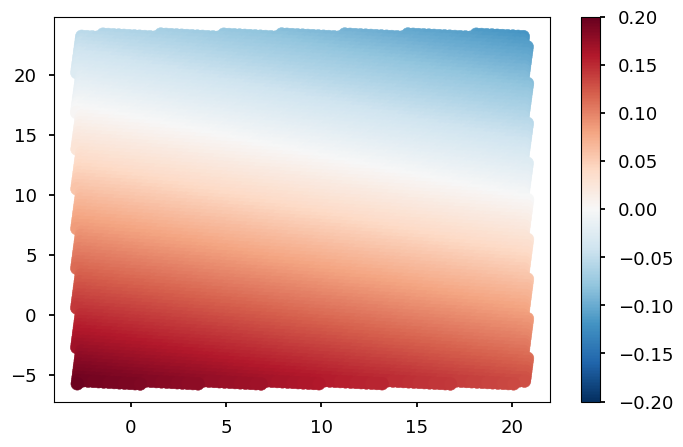

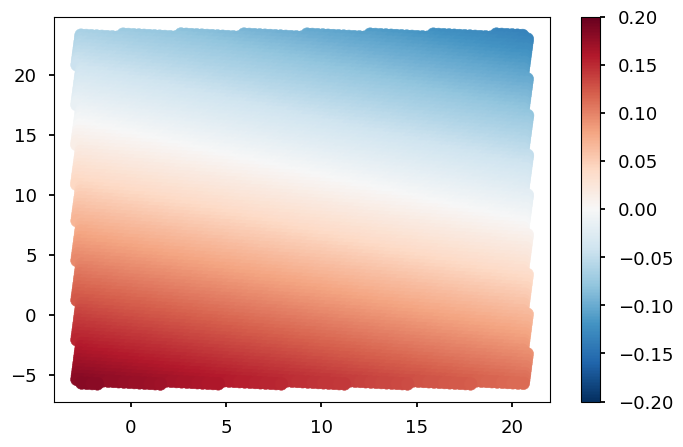

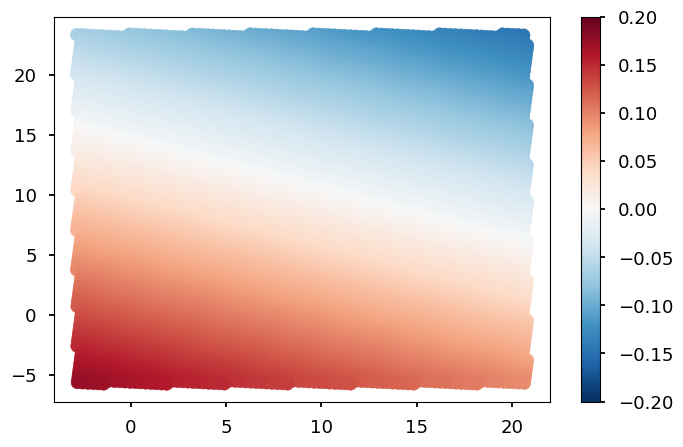

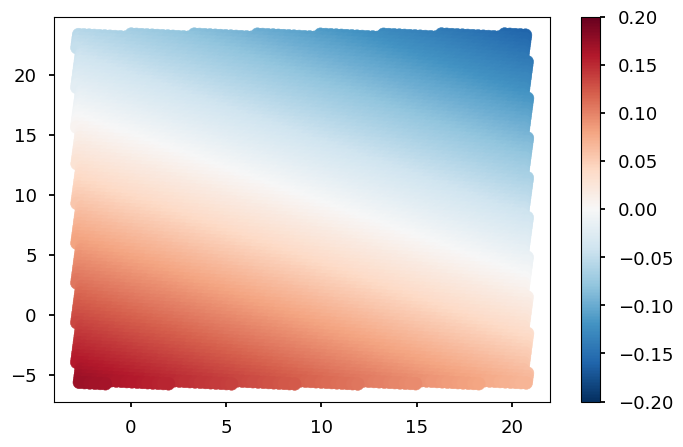

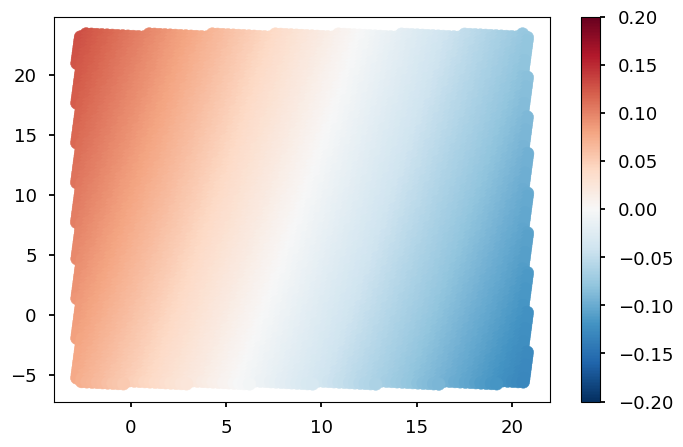

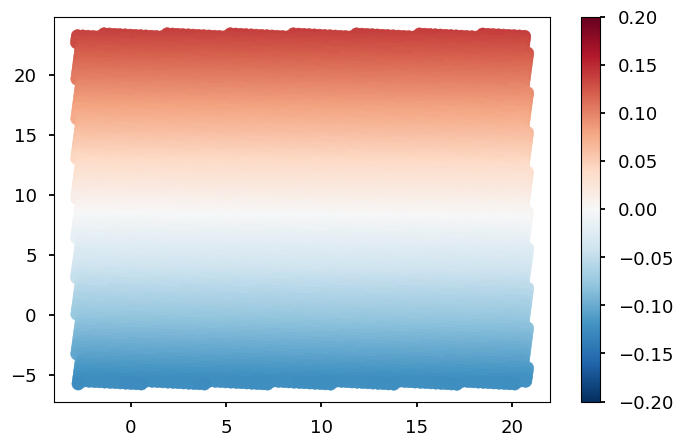

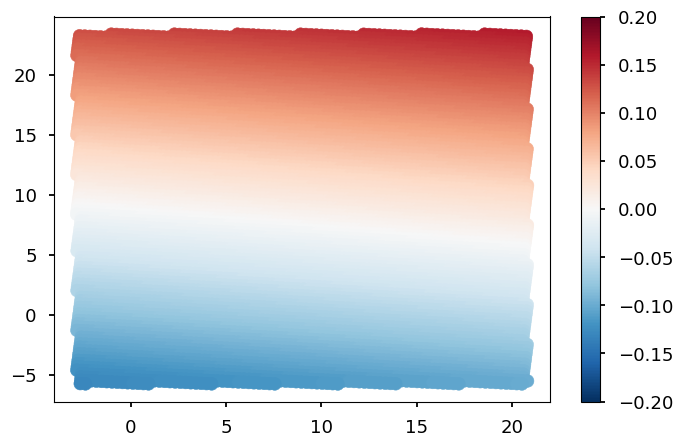

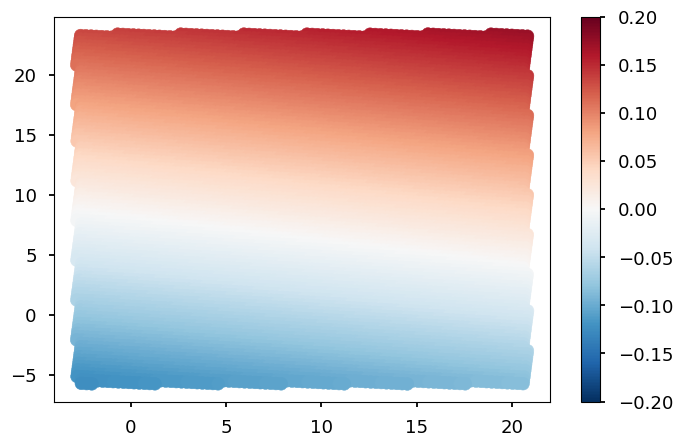

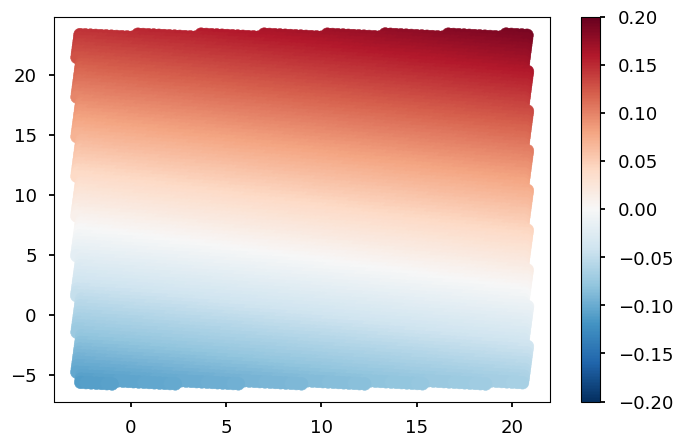

In [24]:
for i in range(9):
    f, ax = plt.subplots(1, 1, figsize=(8, 5))
    sensor = obs['MISR']['sensor_list'][i]
    vza = misr_obs.VZA_center.data[i]
    cbar = ax.scatter(sensor.ray_x.data, sensor.ray_y.data, c= vza - np.degrees(np.arccos(sensor.ray_mu.data)), cmap='RdBu_r', vmin=-0.2, vmax=0.2)
    max_diff = np.max(np.abs(vza - np.degrees(np.arccos(sensor.ray_mu.data))))
    print(max_diff)
    plt.colorbar(cbar)

0.015457187870936195
0.04454574231187536
0.10481238829714812
0.2677811127103702
1.2195705551808578
0.25226696455283815
0.1569818757517254
0.10977107938434472
0.08292013536105003


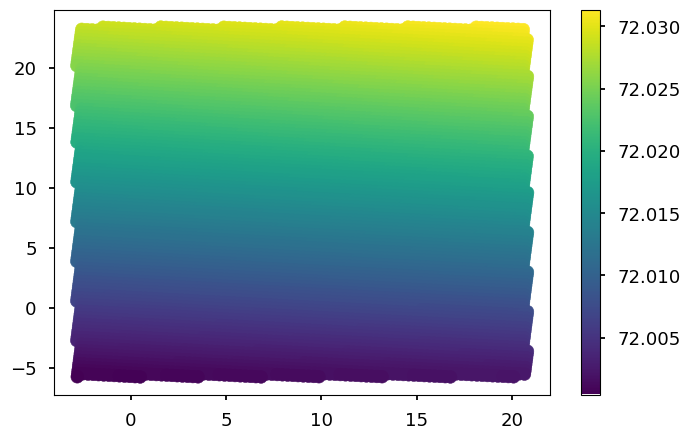

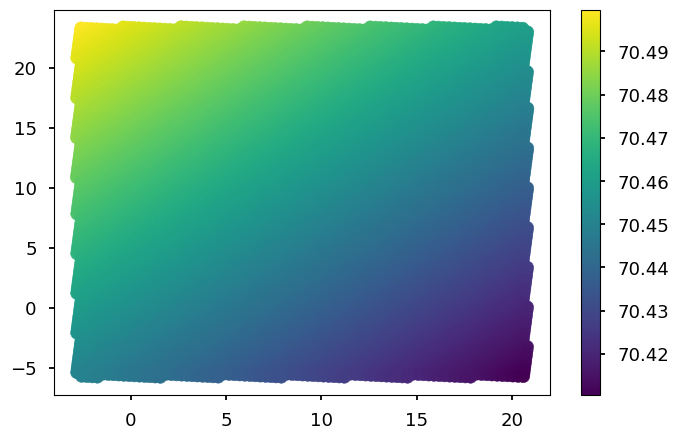

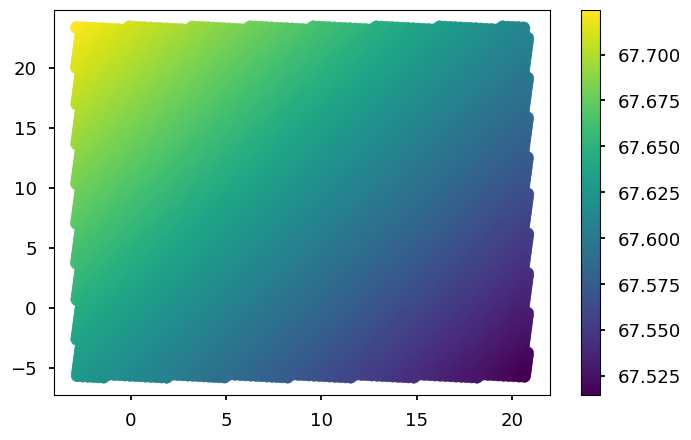

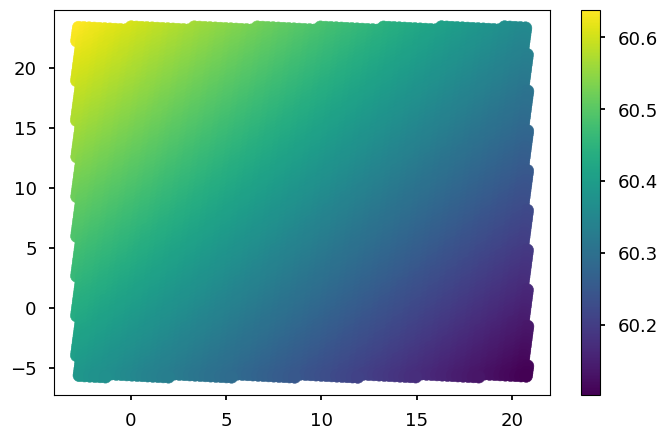

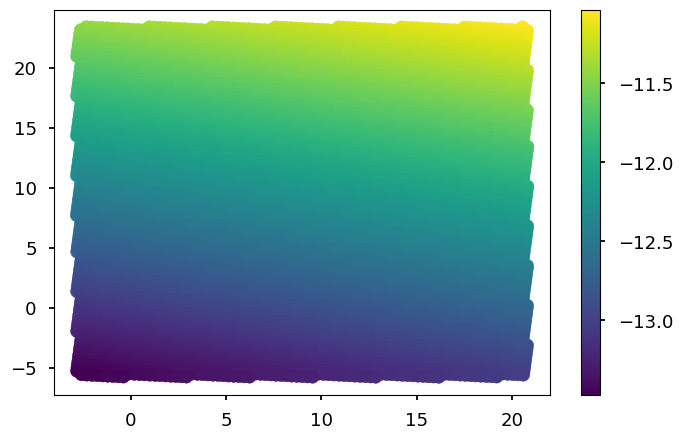

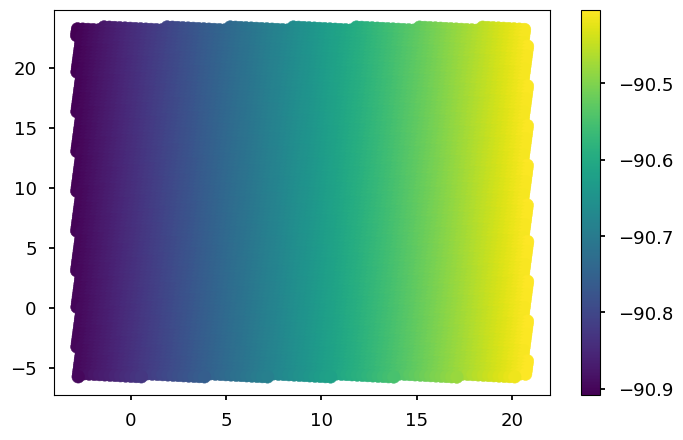

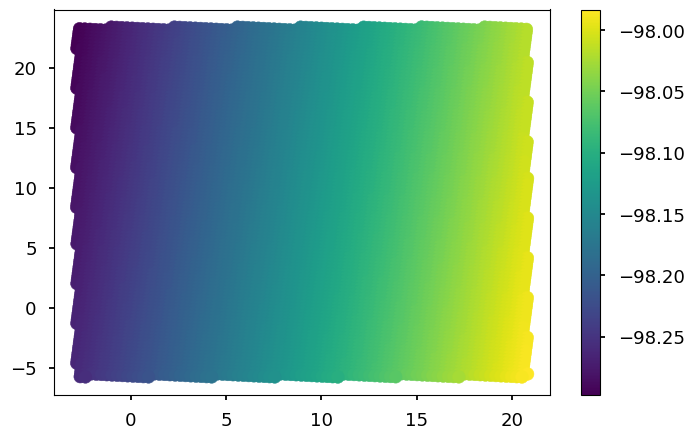

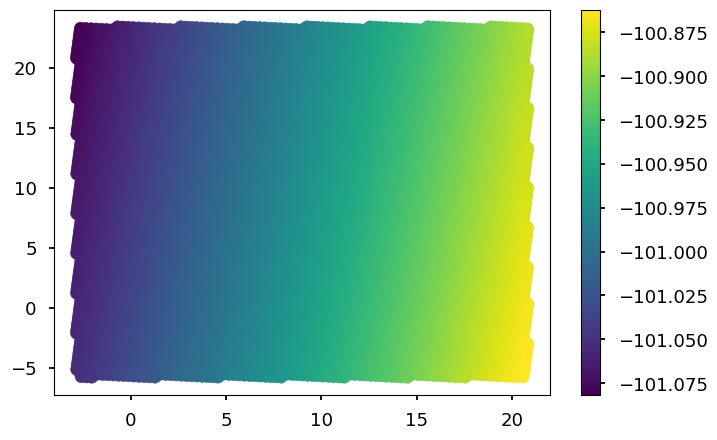

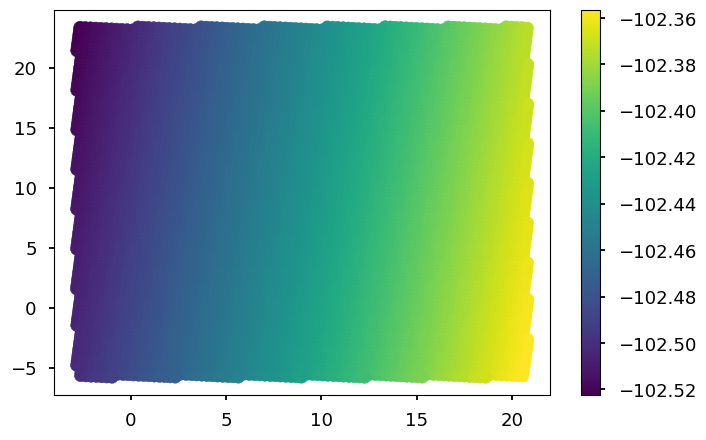

In [26]:
for i in range(9):
    f, ax = plt.subplots(1, 1, figsize=(8, 5))
    sensor = obs['MISR']['sensor_list'][i]
    vaa = misr_obs.VAA_center.data[i]
    cbar = ax.scatter(sensor.ray_x.data, sensor.ray_y.data, c= np.degrees(sensor.ray_phi.data))#, cmap='RdBu_r', vmin=-0.2, vmax=0.2)
    max_diff = (np.max(np.abs(np.degrees(sensor.ray_phi.data))) - np.min(np.abs(np.degrees(sensor.ray_phi.data))))/2
    print(max_diff)
    plt.colorbar(cbar)